# 01 — Обзор и качество не-новостных данных

Карта всех таблиц из `processed.zip` (сбор не-новостных источников): что лежит, с какой
частотой, за какой период, сколько пропусков, где ошибки типов и дат и когда каждый источник
становится доступен (для anti-leakage). Подробный разбор каждого блока — в ноутбуках 02–06.

Данные: все `*.parquet` в `eda/data/processed/` (кроме `news/` — там только README).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import eda_utils as u

u.setup_style()
pd.set_option("display.max_colwidth", 90)
files = sorted(p for p in u.DATA.rglob("*.parquet"))
tables = {str(p.relative_to(u.DATA)): pd.read_parquet(p) for p in files}
print(f"Файлов: {len(tables)}")

Файлов: 31


## 1. Инвентарь таблиц

Для таблиц-рядов указана основная временная колонка; частота — медианный шаг между
уникальными датами. Остальные таблицы — справочники или снимки на дату сбора.

In [2]:
TIME_COLUMNS = {
    "consensus/myfxbook_eia_consensus.parquet": "release_date",
    "consensus/trendonify_api_crude_2015_2016.parquet": "reference_week_end",
    "consensus/trendonify_api_crude_full_history.parquet": "reference_week_end",
    "eia/eia_weekly_features.parquet": "period",
    "eia/eia_wti_futures_features_2015_2024.parquet": "period",
    "fred/fred_daily_features.parquet": "date",
    "fred/fred_monthly_features_current.parquet": "date",
    "market/barchart_wti_curve_2015_onward.parquet": "trading_day",
    "market/barchart_wti_nearbys_2015_onward.parquet": "trading_day",
    "infrastructure/bsee_production_by_complex_month_2015plus.parquet": "production_date",
    "infrastructure/bsee_production_by_structure_2015plus.parquet": "production_date",
    "infrastructure/nhc_hurdat2_atlantic_2015_2025.parquet": "datetime",
    "infrastructure/eia_refineries_model_ready.parquet": "effective_date",
    "infrastructure/eia_refineries_territories_other.parquet": "effective_date",
}


def frequency(dates: pd.Series) -> str:
    """Медианный шаг между уникальными датами словами."""

    step = dates.dropna().drop_duplicates().sort_values().diff().median()
    days = step / pd.Timedelta(days=1)
    for limit, name in ((0.5, "внутридневная"), (1.5, "дневная"), (8, "недельная"), (32, "месячная"), (370, "годовая")):
        if days <= limit:
            return name
    return f"{days:.0f} дн."


rows = []
for name, df in tables.items():
    column = TIME_COLUMNS.get(name)
    dates = df[column].dt.tz_localize(None) if column and df[column].dt.tz is not None else (df[column] if column else None)
    rows.append(
        {
            "таблица": name,
            "строк": len(df),
            "колонок": df.shape[1],
            "время": column or "—",
            "с": f"{dates.min():%Y-%m-%d}" if column else "—",
            "по": f"{dates.max():%Y-%m-%d}" if column else "—",
            "частота": frequency(dates) if column else "снимок/справочник",
            "пропусков, % ячеек": round(100 * df.isna().to_numpy().mean(), 1),
            "дублей строк": int(df.astype(str).duplicated().sum()),
        },
    )
inventory = pd.DataFrame(rows)
inventory

,таблица,строк,колонок,время,с,по,частота,"пропусков, % ячеек",дублей строк
0,consensus/myfxbook_eia_consensus.parquet,616,6,release_date,2015-01-07,2026-11-04,недельная,0.0,0
1,consensus/trendonify_api_crude_2015_2016.parquet,105,10,reference_week_end,2015-01-02,2016-12-30,недельная,0.0,0
2,consensus/trendonify_api_crude_full_history.parquet,753,10,reference_week_end,2012-03-23,2026-10-30,недельная,0.0,0
3,eia/eia_weekly_features.parquet,610,39,period,2015-02-20,2026-10-23,недельная,0.0,0
4,eia/eia_wti_futures_features_2015_2024.parquet,2305,11,period,2015-02-19,2024-04-05,дневная,0.0,0
5,fred/fred_daily_features.parquet,4276,28,date,2015-02-19,2026-11-03,дневная,27.0,0
6,fred/fred_monthly_features_current.parquet,140,7,date,2015-02-01,2026-09-01,месячная,3.1,0
7,infrastructure/boem_platforms_current.parquet,1315,6,—,—,—,снимок/справочник,16.7,0
8,infrastructure/bsee_offshore_crude_pipelines.parquet,7030,48,—,—,—,снимок/справочник,34.0,0
9,infrastructure/bsee_offshore_pipelines.parquet,21314,48,—,—,—,снимок/справочник,31.5,0


In [3]:
by_block = inventory.assign(блок=inventory["таблица"].str.split("/").str[0]).groupby("блок").agg(
    таблиц=("таблица", "size"),
    строк=("строк", "sum"),
)
by_block

,таблиц,строк
блок,,
consensus,3,1474
eia,2,2915
fred,2,4416
infrastructure,21,600094
market,3,23855


**Вывод.** 31 таблица (плюс CSV-копия консенсуса): 14 временных рядов и 17 справочников или
снимков; почти все строки — инфраструктура (600 тыс. из 633 тыс.). Дубли есть только в
`gem_pipeline_ownership_all` (69 строк). В ключевых рядах пропусков почти нет: EIA, консенсус,
API, Barchart — 0% ячеек; FRED daily — 27% (календарные дни, выходные пусты по построению);
у nearbys 7.1% — это колонка `open_interest`, пустая целиком.

## 2. Покрытие по времени

Период проекта — 2015–2026. Полоса — от первой до последней даты ряда.

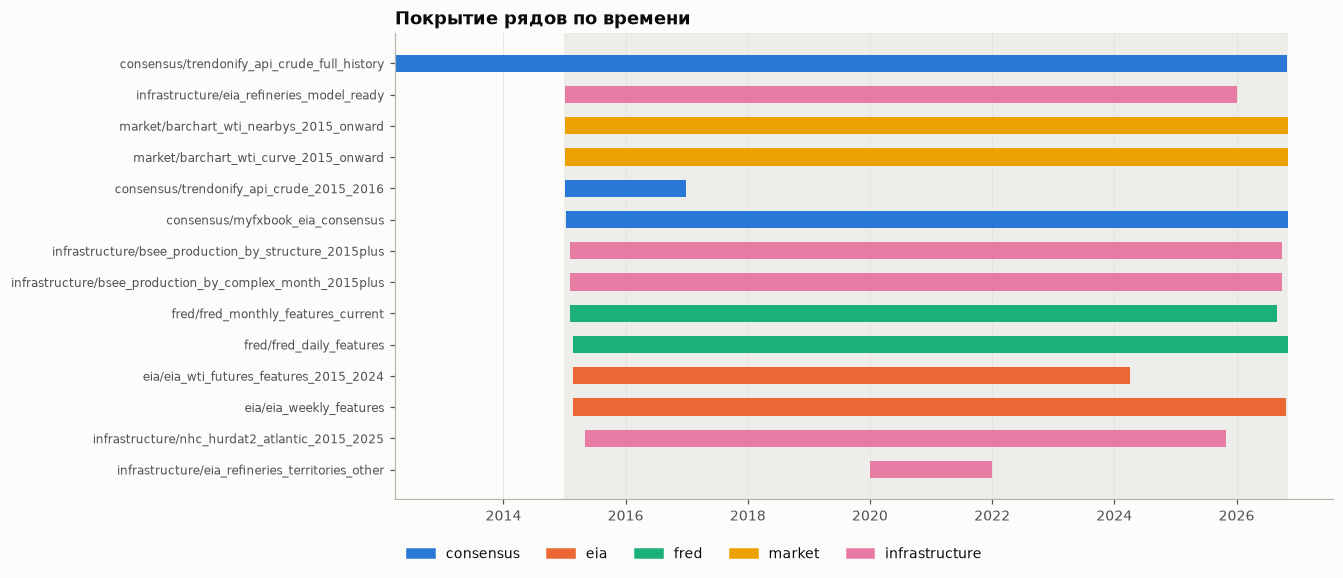

In [4]:
series = inventory[inventory["время"] != "—"].copy()
series["start"] = pd.to_datetime(series["с"])
series["end"] = pd.to_datetime(series["по"])
series = series.sort_values("start", ascending=False).reset_index(drop=True)
block_color = {block: u.SERIES[i] for i, block in enumerate(["consensus", "eia", "fred", "market", "infrastructure"])}

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(pd.Timestamp("2015-01-01"), pd.Timestamp("2026-11-01"), color=u.GRID, alpha=0.6, label="период проекта")
for i, row in series.iterrows():
    block = row["таблица"].split("/")[0]
    ax.barh(i, row["end"] - row["start"], left=row["start"], height=0.55, color=block_color[block])
ax.set_yticks(range(len(series)), series["таблица"].str.replace(".parquet", "", regex=False), fontsize=8)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in block_color.values()]
ax.legend(handles, block_color.keys(), loc="lower left", ncols=5, bbox_to_anchor=(0, -0.16))
ax.set_title("Покрытие рядов по времени")
plt.show()

**Вывод.** Рыночные и фундаментальные ряды покрывают весь период проекта; общий старт —
2015-02-19/20 (EIA weekly и FRED; та же дата начала, что у новостей в `src/news`). EIA futures
обрываются 2024-04-05 — для спрэда нужен Barchart, а EIA futures годятся только для сверки. API
(Trendonify) есть с 2012-03. HURDAT2 — по сезон 2025 включительно, сезона 2026 нет.

## 3. Пропуски в основных рядах по годам

Доля пропусков по колонкам и годам для трёх широких рядов, на которых строится недельная
модель. FRED — только по рабочим дням (выходные пусты по построению).

EIA, недели: колонок 38, с пропусками хоть в одном году — 10, максимум 2.2%
FRED, рабочие дни: колонок 8, с пропусками хоть в одном году — 8, максимум 5.0%
Barchart, торговые дни: колонок 7, с пропусками хоть в одном году — 0, максимум 0.0%


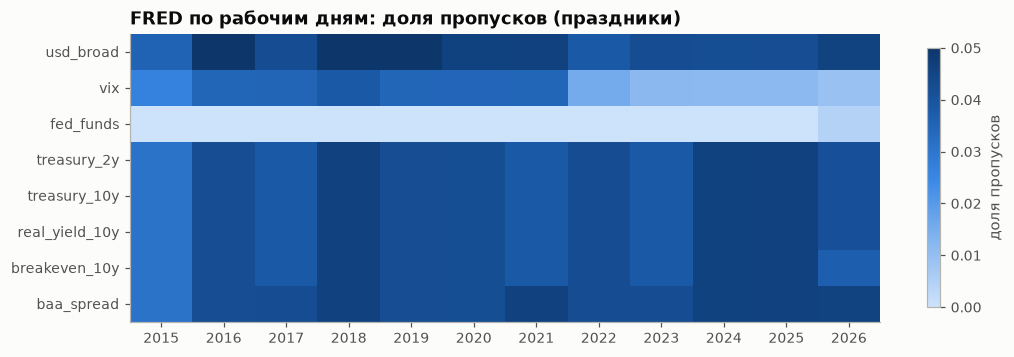

In [5]:
def missing_by_year(df: pd.DataFrame, time: str) -> pd.DataFrame:
    """Доля пропусков: колонки × годы."""

    values = df.drop(columns=[time]).select_dtypes("number")
    return values.isna().groupby(df[time].dt.year).mean().T


fred = tables["fred/fred_daily_features.parquet"]
fred_business = fred[fred["date"].dt.day_of_week < 5]
panels = {
    "EIA, недели": missing_by_year(tables["eia/eia_weekly_features.parquet"], "period"),
    "FRED, рабочие дни": missing_by_year(fred_business[["date", "usd_broad", "vix", "fed_funds", "treasury_2y", "treasury_10y", "real_yield_10y", "breakeven_10y", "baa_spread"]], "date"),
    "Barchart, торговые дни": missing_by_year(tables["market/barchart_wti_curve_2015_onward.parquet"][["trading_day", "wti_f1", "wti_f2", "wti_f3", "wti_f4", "wti_f5", "wti_f6", "wti_f12"]], "trading_day"),
}
for title, matrix in panels.items():
    worst = matrix.max(axis=1)
    print(f"{title}: колонок {len(matrix)}, с пропусками хоть в одном году — {(worst > 0).sum()}, максимум {worst.max():.1%}")

fig, ax = plt.subplots(figsize=(11, 3.4))
matrix = panels["FRED, рабочие дни"]
image = ax.imshow(matrix.to_numpy(), aspect="auto", cmap=u.SEQUENTIAL, vmin=0, vmax=max(0.05, matrix.to_numpy().max()))
ax.set_xticks(range(matrix.shape[1]), matrix.columns)
ax.set_yticks(range(matrix.shape[0]), matrix.index)
ax.grid(False)
fig.colorbar(image, ax=ax, label="доля пропусков", shrink=0.9)
ax.set_title("FRED по рабочим дням: доля пропусков (праздники)")
plt.show()

In [6]:
holidays = fred_business[fred_business["vix"].isna() | fred_business["usd_broad"].isna()]
print(f"Рабочих дней FRED с пропуском VIX или USD: {len(holidays)} из {len(fred_business)}")
holidays.assign(месяц_день=holidays["date"].dt.strftime("%m-%d"))["месяц_день"].value_counts().head(10)

Рабочих дней FRED с пропуском VIX или USD: 147 из 3054


месяц_день
11-11    8
12-25    8
01-01    8
07-04    8
01-20    4
06-19    4
05-25    3
07-03    3
09-07    3
10-12    3
Name: count, dtype: int64

**Вывод.** В EIA weekly пропуски только в первой строке колонок изменений (10 колонок, 2015 г.)
— следствие разностей. В Barchart пропусков нет. В FRED 147 из 3054 рабочих дней без VIX или
USD — это праздники рынка облигаций США (11-11, 12-25, 01-01, 07-04 — по 8 раз и т. д.), а не
потери данных. При агрегации FRED до недели — последнее известное значение внутри недели, без
интерполяции через будущие дни.

## 4. Ошибки типов и дат

Даты вне диапазона 1900–2027 и числовые значения, сохранённые строками.

In [7]:
bad_dates = []
for name, df in tables.items():
    for column in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[column]):
            years = df[column].dt.year
            bad = df[column][(years < 1900) | (years > 2027)]
            if len(bad):
                bad_dates.append(
                    {
                        "таблица": name,
                        "колонка": column,
                        "неверных": len(bad),
                        "из непустых": int(df[column].notna().sum()),
                        "примеры": ", ".join(sorted({f"{d:%Y-%m-%d}" for d in bad})[:4]),
                    },
                )
pd.DataFrame(bad_dates)

,таблица,колонка,неверных,из непустых,примеры
0,infrastructure/bsee_offshore_crude_pipelines.parquet,aban_date,3,2426,1870-03-01
1,infrastructure/bsee_offshore_pipelines.parquet,aban_date,10,9953,1870-03-01
2,infrastructure/bsee_pipeline_history_events.parquet,history_date,9,85139,"18-04-15, 19-09-20, 199-11-19, 20-07-24"


In [8]:
numeric_as_text = []
for name, df in tables.items():
    for column in df.columns:
        if pd.api.types.is_string_dtype(df[column]) or df[column].dtype == object:
            values = df[column].dropna()
            if len(values) < 20:
                continue
            parsed = pd.to_numeric(values, errors="coerce")
            share = parsed.notna().mean()
            if share > 0.95 and values.astype(str).str.len().max() < 20:
                numeric_as_text.append({"таблица": name, "колонка": column, "доля чисел": round(share, 3), "пример": values.iloc[0]})
text_numbers = pd.DataFrame(numeric_as_text)
print(f"Колонок «число строкой»: {len(text_numbers)}")
text_numbers.groupby("таблица")["колонка"].apply(lambda c: ", ".join(c)).to_frame("колонки").style.set_properties(**{"white-space": "normal"})

Колонок «число строкой»: 34


,колонки
таблица,
infrastructure/bsee_offshore_crude_pipelines.parquet,"seg_length, orig_blk_num, dest_blk_num, cat_life_tm, fed_st_lgth, ppl_size_code, recv_maop_prss, ppl_row_prmte, facil_operator, min_wtr_dpth, max_wtr_dpth, maop_prss"
infrastructure/bsee_offshore_pipelines.parquet,"seg_length, orig_blk_num, dest_blk_num, cat_life_tm, fed_st_lgth, ppl_size_code, recv_maop_prss, ppl_row_prmte, facil_operator, min_wtr_dpth, max_wtr_dpth, maop_prss"
infrastructure/bsee_platform_history.parquet,"deck_count, slant_slot_count, slot_count, slot_drill_count, satellite_completion_count, surface_east_west_distance, surface_north_south_distance, underwater_completion_count, district_code"
infrastructure/bsee_production_by_structure_2015plus.parquet,block_number


**Вывод.** Невозможные даты: `aban_date` = 1870-03-01 в 10 строках `bsee_offshore_pipelines`
(3 из них есть и в crude-версии) и 9 значений `history_date` в `bsee_pipeline_history_events` с
годами вроде 18, 19, 199 и 7001 — опечатки исходных данных BSEE, при построении графа их нужно
обнулять. 34 колонки BSEE (длины сегментов, число палуб и слотов, номера блоков) хранятся
строками: номера блоков — это коды, их оставить строками; длины и счётчики привести к числам.

## 5. Когда данные становятся известны (anti-leakage)

Для каждой недели модели нужно знать, что было опубликовано до релиза EIA (среда, 10:30 ET).
Ниже — время доступности по источникам: что подтверждается колонками самих таблиц и что
остаётся допущением.

In [9]:
flags = []
for name, df in tables.items():
    for column in df.columns:
        if any(key in column for key in ("safe", "available", "fetched", "downloaded", "snapshot", "availability", "point_in_time")):
            values = df[column].dropna()
            sample = values.unique()[:3] if not pd.api.types.is_datetime64_any_dtype(values) else [f"{values.min():%Y-%m-%d}", f"{values.max():%Y-%m-%d}"]
            flags.append({"таблица": name, "колонка": column, "значения": ", ".join(map(str, sample))})
pd.DataFrame(flags)

,таблица,колонка,значения
0,consensus/trendonify_api_crude_2015_2016.parquet,fetched_at_utc,"2026-11-06, 2026-11-06"
1,consensus/trendonify_api_crude_full_history.parquet,fetched_at_utc,"2026-11-06, 2026-11-06"
2,infrastructure/eia_refineries_model_ready.parquet,safe_available_from,"2016-01-01, 2027-01-01"
3,infrastructure/eia_refineries_model_ready.parquet,availability_rule,conservative_one_year_lag
4,infrastructure/eia_refineries_territories_other.parquet,safe_available_from,"2021-01-01, 2023-01-01"
5,infrastructure/eia_refineries_territories_other.parquet,availability_rule,conservative_one_year_lag
6,infrastructure/gem_oil_pipelines_temporal.parquet,source_snapshot,GOIT 2026-06
7,infrastructure/gem_pipeline_ownership_us_snapshot_2026_10.parquet,ownership_snapshot,2026-10
8,infrastructure/gem_pipeline_ownership_us_snapshot_2026_10.parquet,point_in_time_historical_safe,False
9,infrastructure/nhc_hurdat2_atlantic_2015_2025.parquet,point_in_time_safe,False


In [10]:
availability = pd.DataFrame(
    [
        ("EIA WPSR (запасы, баланс)", "среда 10:30 ET; праздники — чт/пт/пн", "дата релиза из Myfxbook", "таргет и история; данные EIA API пересмотрены — факт брать из первой публикации"),
        ("Консенсус Myfxbook", "до релиза EIA", "не подтверждено: в таблице нет времени фиксации", "проверить, обновляется ли после API"),
        ("API (Trendonify)", "вторник 16:30 ET", "нет времени публикации, только неделя отчёта", "известен до EIA — легальный признак"),
        ("Barchart WTI", "закрытие торгового дня (CST)", "trading_day; downloaded_at 2026-11-05", "для недели t брать закрытие вторника или раньше"),
        ("EIA WTI futures", "закрытие торгового дня", "period", "только до 2024-04-05 — для сверки"),
        ("FRED daily", "наблюдение дня t доступно с задержкой до 1 дня", "date — дата наблюдения, не публикации", "сдвигать на 1 рабочий день"),
        ("FRED monthly", "публикация через 2–6 недель после месяца", "текущая (пересмотренная) версия", "лаг публикации + исходные выпуски, иначе утечка пересмотров"),
        ("BSEE добыча", "месячные отчёты операторов с задержкой", "production_date — месяц добычи", "лаг публикации не известен из данных"),
        ("НПЗ EIA (годовые)", "ежегодный отчёт", "safe_available_from = effective_date + 1 год", "правило консервативного лага уже применено"),
        ("GEM GOIT", "снимок 2026-06", "source_snapshot, ownership_snapshot", "не point-in-time: статусы и владельцы на 2026 год"),
        ("HURDAT2", "финальный best track после сезона", "point_in_time_safe = False", "для недели t нужны оперативные данные NHC, а не best track"),
        ("OSM", "текущий снимок", "нет дат", "только статичная справка"),
    ],
    columns=["источник", "когда известно", "что видно в данных", "как использовать"],
)
availability

,источник,когда известно,что видно в данных,как использовать
0,"EIA WPSR (запасы, баланс)",среда 10:30 ET; праздники — чт/пт/пн,дата релиза из Myfxbook,таргет и история; данные EIA API пересмотрены — факт брать из первой публикации
1,Консенсус Myfxbook,до релиза EIA,не подтверждено: в таблице нет времени фиксации,"проверить, обновляется ли после API"
2,API (Trendonify),вторник 16:30 ET,"нет времени публикации, только неделя отчёта",известен до EIA — легальный признак
3,Barchart WTI,закрытие торгового дня (CST),trading_day; downloaded_at 2026-11-05,для недели t брать закрытие вторника или раньше
4,EIA WTI futures,закрытие торгового дня,period,только до 2024-04-05 — для сверки
5,FRED daily,наблюдение дня t доступно с задержкой до 1 дня,"date — дата наблюдения, не публикации",сдвигать на 1 рабочий день
6,FRED monthly,публикация через 2–6 недель после месяца,текущая (пересмотренная) версия,"лаг публикации + исходные выпуски, иначе утечка пересмотров"
7,BSEE добыча,месячные отчёты операторов с задержкой,production_date — месяц добычи,лаг публикации не известен из данных
8,НПЗ EIA (годовые),ежегодный отчёт,safe_available_from = effective_date + 1 год,правило консервативного лага уже применено
9,GEM GOIT,снимок 2026-06,"source_snapshot, ownership_snapshot",не point-in-time: статусы и владельцы на 2026 год


**Вывод.** Явные метки доступности есть только у НПЗ (`safe_available_from`, лаг 1 год),
снимков GEM (2026-06 и 2026-10, `point_in_time_historical_safe = False`) и HURDAT2
(`point_in_time_safe = False`). У EIA, API, консенсуса и рынка есть только дата наблюдения —
время публикации задаётся правилом. Две зоны риска утечки: (1) FRED monthly и BSEE —
пересмотренные значения без даты публикации; (2) GEM, OSM и best track HURDAT описывают
состояние на 2025–2026 гг., для прошлых недель это знание из будущего.

## 6. Общая недельная сетка

Сколько недель отчёта EIA 2015–2026 покрыты каждым источником (хотя бы одно наблюдение в
неделе до релиза).

In [11]:
frame = u.release_frame()
weeks = frame[["release_date", "period"]].copy()
weeks["week_start"] = weeks["period"] - pd.Timedelta(days=6)


def weekly_presence(dates: pd.Series) -> pd.Series:
    """Есть ли наблюдения в окне [конец прошлой недели отчёта; день до релиза]."""

    stamps = np.sort(dates.dropna().unique())
    left = np.searchsorted(stamps, weeks["week_start"].to_numpy(), side="left")
    right = np.searchsorted(stamps, (weeks["release_date"] - pd.Timedelta(days=1)).to_numpy(), side="right")
    return pd.Series(right > left, index=weeks.index)


curve = tables["market/barchart_wti_curve_2015_onward.parquet"]
presence = pd.DataFrame(
    {
        "EIA weekly": weeks["period"].isin(tables["eia/eia_weekly_features.parquet"]["period"]),
        "консенсус": frame["consensus_mmbbl"].notna(),
        "API": frame["api_mmbbl"].notna(),
        "Barchart": weekly_presence(curve.loc[curve["wti_f1"].notna(), "trading_day"]),
        "EIA futures": weekly_presence(tables["eia/eia_wti_futures_features_2015_2024.parquet"]["period"]),
        "FRED daily": weekly_presence(fred.loc[fred["vix"].notna(), "date"]),
    },
)
presence.index = weeks["release_date"]
summary = presence.groupby(presence.index.year).mean().T
print(f"Недель отчёта: {len(presence)}; все источники кроме EIA futures: {presence.drop(columns='EIA futures').all(axis=1).sum()}")
summary.round(2)

Недель отчёта: 616; все источники кроме EIA futures: 608


release_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
EIA weekly,0.87,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,0.98
консенсус,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.00
API,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.00
Barchart,1.00,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.00
EIA futures,0.87,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.29,0.0,0.00
FRED daily,0.87,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.00


**Вывод.** Из 616 недель отчёта все ключевые источники (EIA weekly, консенсус, API, Barchart,
FRED) есть в 608. Пробелы — семь релизов начала 2015 г. (EIA и FRED начинаются 2015-02-19/20) и
последний релиз 2026-11-04 (EIA weekly заканчивается неделей 2026-10-23). EIA futures покрывают
недели только до апреля 2024.

## Итоги

- **Состав:** 31 таблица, 14 временных рядов и 17 справочников/снимков; общий период рядов —
  2015-02-19 – 2026-10/11.
- **Таргет и рынок готовы:** EIA weekly, консенсус, API и Barchart без пропусков и дублей;
  608 из 616 недель покрыты всеми ключевыми источниками.
- **Ошибки данных:** 13 строк с `aban_date` 1870 года, 9 невозможных `history_date`, 69 дублей в
  `gem_pipeline_ownership_all`, 34 числовые колонки BSEE хранятся строками, `open_interest`
  в Barchart пуст целиком.
- **Ограничения покрытия:** EIA futures только до 2024-04, HURDAT2 до 2025, Myfxbook без двух
  недель (2022-06-17, 2023-11-03, см. ноутбук 03).
- **Anti-leakage:** правила доступности нужны для каждого источника (таблица в разделе 5);
  опаснее всего пересмотренные FRED monthly и BSEE и снимки GEM, OSM, HURDAT2 — их нельзя
  использовать для прошлых недель как есть.